In [1]:
import torch
import monai
import numpy as np

print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("gpu:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("monai:", monai.__version__)
print("numpy:", np.__version__)

torch: 2.7.1+cu118
cuda available: True
gpu: NVIDIA GeForce RTX 3050 6GB Laptop GPU
monai: 1.4.0
numpy: 1.26.4


In [2]:
import torch

x = torch.randn(3000, 3000).cuda()
y = torch.mm(x, x)

print("GPU OK")
print(torch.cuda.get_device_name(0))

GPU OK
NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
import torch
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM free test OK")

CUDA: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM free test OK



🧩 MedSSL-3D v0.5 — Mode B: Segmentation head

🧪 ENVIRONMENT REPORT
Python      : 3.10.20
PyTorch     : 2.7.1+cu118
MONAI       : 1.4.0
NumPy       : 1.26.4
CUDA avail. : True
GPU         : NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory  : 6.0 GB
Device used : cuda
Run mode    : segmentation
🔒 Seed set to 42

📂 DATA_ROOT : C:/Users/ILIA/Desktop/MedSSL_v0/MICCAI_BraTS2020_TrainingData
📂 MODALITY  : flair
📂 Seg checkpoints -> C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\segmentation
📂 Seg logs        -> C:\Users\ILIA\Desktop\MedSSL_Results\logs\segmentation

🔍 DATA SANITY CHECK (Mode B — Segmentation)
✅ Directory exists: C:/Users/ILIA/Desktop/MedSSL_v0/MICCAI_BraTS2020_TrainingData
✅ Found 369 'flair' file(s)
⚠️ 1 image file(s) had no matching segmentation mask and were skipped.
✅ Matched 368 (image, mask) pair(s)
📄 First pair:
   image: BraTS20_Training_001_flair.nii
   mask : BraTS20_Training_001_seg.nii
📦 Volume shape: (1, 128, 128, 64) | Mask shape: (1, 128, 128, 64)
🏷️ Raw ma

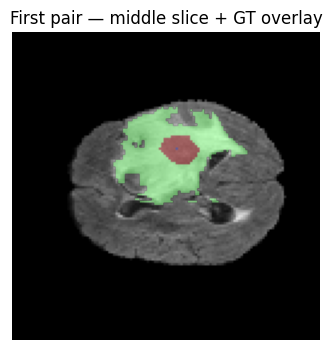

✅ Middle slice + ground-truth overlay displayed above.

✅ SEGMENTATION SANITY CHECK PASSED.


📊 Train pairs: 294 | Val pairs: 74
Encoder path: C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\encoder.pth
Exists? True
Checkpoint dir: C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints
Files: ['best_model.pth', 'checkpoint_epoch_1.pth', 'checkpoint_epoch_10.pth', 'checkpoint_epoch_11.pth', 'checkpoint_epoch_12.pth', 'checkpoint_epoch_13.pth', 'checkpoint_epoch_14.pth', 'checkpoint_epoch_15.pth', 'checkpoint_epoch_16.pth', 'checkpoint_epoch_17.pth', 'checkpoint_epoch_18.pth', 'checkpoint_epoch_19.pth', 'checkpoint_epoch_2.pth', 'checkpoint_epoch_20.pth', 'checkpoint_epoch_3.pth', 'checkpoint_epoch_4.pth', 'checkpoint_epoch_5.pth', 'checkpoint_epoch_6.pth', 'checkpoint_epoch_7.pth', 'checkpoint_epoch_8.pth', 'checkpoint_epoch_9.pth', 'config.json', 'encoder.pth', 'segmentation']
✅ Loaded pretrained SSL encoder from C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\encoder.pth

----------------

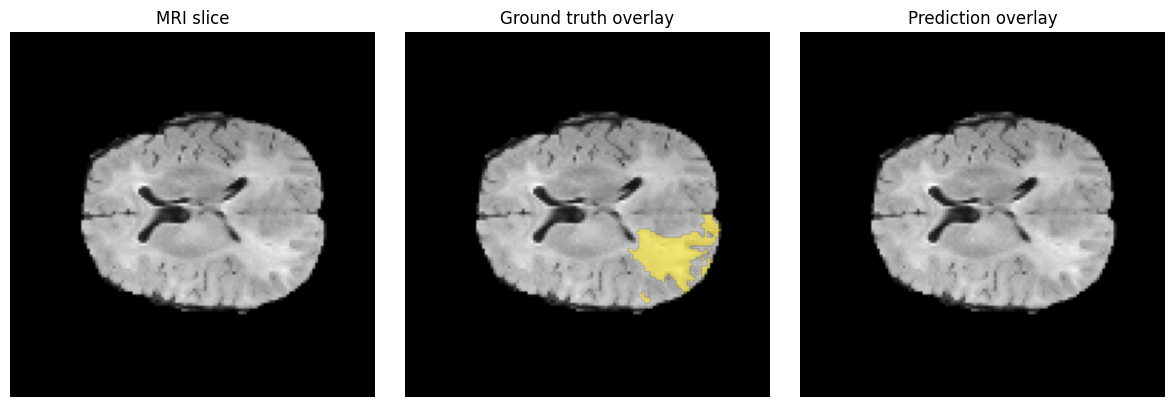

📊 Val Dice: 0.2150 | Val IoU: 0.1342
✅ New best segmentation model saved (Dice: 0.2150)
💾 Segmentation history saved to C:\Users\ILIA\Desktop\MedSSL_Results\logs\segmentation/segmentation_history.csv


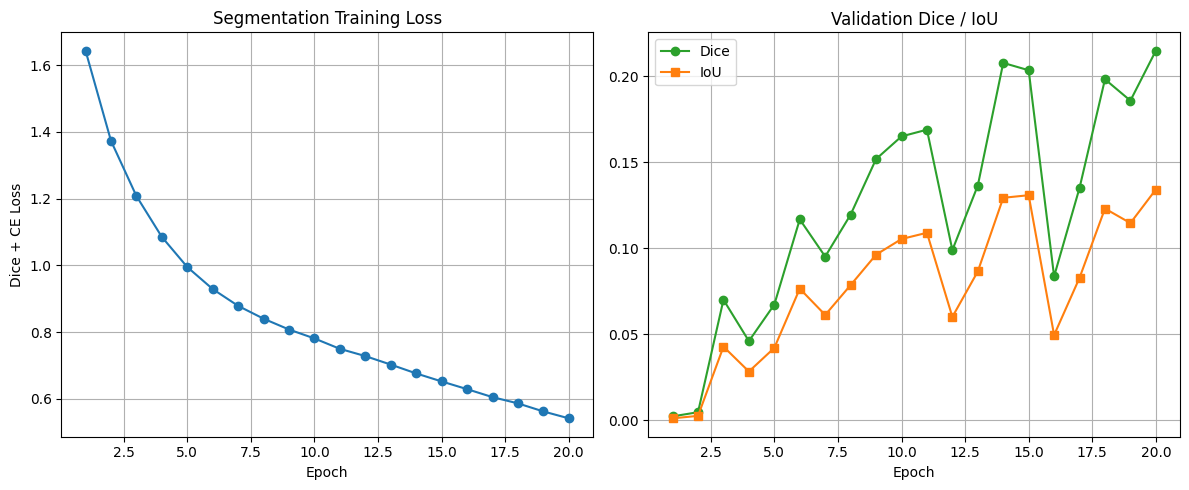


🎉 v0.5 Mode B RUN COMPLETE
💾 Checkpoints -> C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\segmentation
💾 Logs        -> C:\Users\ILIA\Desktop\MedSSL_Results\logs\segmentation
📌 SimCLR pipeline (Mode A) is untouched — set Config.MODE='simclr' to confirm.


In [5]:
# ==============================================================================
# MedSSL-3D v0.5
# Self-Supervised 3D Medical Representation Learning (SimCLR) + a lightweight
# segmentation head, built directly on top of the verified v0.4 pipeline.
#
# Single Google Colab / Jupyter cell — single continuous run.
#
# WHAT'S NEW IN v0.5 (vs v0.4):
#   - ResNet3D.forward() gained an optional `return_feature_map` argument.
#     Called with no arguments (as SimCLR3D does), it is BYTE-FOR-BYTE
#     IDENTICAL to v0.4 — same ops, same output. Only when explicitly asked
#     does it also return the pre-pool spatial feature map (C, D, H, W).
#     No layer was added, removed, or resized: this is v0.4's architecture
#     with one extra return path, not a rewrite.
#   - A minimal SegmentationHead3D (3x ConvTranspose3D + 2x Conv3D +
#     1x1x1 classifier — NOT a full U-Net, no skip connections) turns that
#     feature map into a voxel-wise prediction.
#   - Two independent run modes, switched with a single Config.MODE flag:
#       MODE = 'simclr'       -> exactly the v0.4 contrastive pretraining
#       MODE = 'segmentation' -> new: loads the pretrained encoder (if
#                                 available) and trains the segmentation head
#     There is no joint/simultaneous training yet, by design.
#
# ONLY LINE YOU SHOULD NEED TO EDIT: Config.DATA_ROOT, below.
#
# Recommended first run: set MODE = 'simclr' once to confirm it behaves
# exactly like v0.4 (it will produce the same checkpoints/encoder.pth).
# Then switch MODE = 'segmentation' to exercise the new v0.5 head — it will
# automatically pick up that encoder.pth if present.
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Install dependencies
#    (This '!' line is Jupyter/Colab notebook-cell syntax. If you ever run this
#    file as a plain .py script instead of a notebook cell, remove this line
#    and install the packages beforehand with a normal `pip install` command.)
# ------------------------------------------------------------------------------
!pip install -q torch torchvision monai nibabel numpy tqdm matplotlib

# ------------------------------------------------------------------------------
# 2. Imports
# ------------------------------------------------------------------------------
import os
import glob
import json
import csv
import random
import logging
import platform
from typing import Tuple, List, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import monai
from monai.transforms import (
    Compose, LoadImage, EnsureChannelFirst, Resize, NormalizeIntensity,
    RandFlip, RandRotate90, RandGaussianNoise, RandScaleIntensity, RandShiftIntensity,
)

import matplotlib.pyplot as plt
from tqdm import tqdm

# ------------------------------------------------------------------------------
# 3. Logging
# ------------------------------------------------------------------------------
logging.basicConfig(level=logging.INFO, format='%(message)s')
logger = logging.getLogger('MedSSL-3D')


def log_section(title: str) -> None:
    logger.info("\n" + "=" * 80)
    logger.info(title)
    logger.info("=" * 80)


# ------------------------------------------------------------------------------
# 4. Config
# ------------------------------------------------------------------------------
class Config:
    SEED = 42
    DEVICE =  'cuda' 

    # ---- Shared by both modes ----
    IMG_SIZE = (128, 128, 64)     # (H, W, D)
    NUM_WORKERS = 0                # keep 0 — safest choice on Colab

    # >>> THE ONLY LINE YOU SHOULD NEED TO EDIT <<<
    DATA_ROOT = 'C:/Users/ILIA/Desktop/MedSSL_v0/MICCAI_BraTS2020_TrainingData'
    MODALITY = 'flair'            # 't1', 't1ce', 't2', or 'flair'

    # ---- Mode switch ----
    MODE = 'segmentation'          # 'simclr' (Mode A, = v0.4 unchanged) or 'segmentation' (Mode B, new)

    # ---- Mode A: SimCLR pretraining (identical defaults to v0.4) ----
    BATCH_SIZE = 8
    PROJECTION_DIM = 128
    TEMPERATURE = 0.5
    LR = 1e-4
    NUM_EPOCHS = 5
    
    # ---- Output directories ----
    DESKTOP_BASE = os.path.join(os.path.expanduser("~"), "Desktop", "MedSSL_Results")
    CHECKPOINT_DIR = os.path.join(DESKTOP_BASE, 'checkpoints')
    LOG_DIR = os.path.join(DESKTOP_BASE, 'logs')
    SEG_CHECKPOINT_DIR = os.path.join(DESKTOP_BASE, 'checkpoints', 'segmentation')
    SEG_LOG_DIR = os.path.join(DESKTOP_BASE, 'logs', 'segmentation')

    # ---- Mode B: Segmentation (new in v0.5) ----
    NUM_SEG_CLASSES = 4            # background, NCR/NET, edema, enhancing (BraTS label 4 -> 3)
    BATCH_SIZE_SEG = 2              # 3D volumes are memory-heavy; lower this further if you hit OOM
    LR_SEG = 1e-4
    NUM_EPOCHS_SEG = 20
    VAL_FRACTION = 0.2
    USE_PRETRAINED_ENCODER = True
    PRETRAINED_ENCODER_PATH = os.path.join(CHECKPOINT_DIR, 'encoder.pth')   # produced by Mode A

    @classmethod
    def setup_dirs(cls) -> None:
        os.makedirs(cls.CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.LOG_DIR, exist_ok=True)
        os.makedirs(cls.SEG_CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.SEG_LOG_DIR, exist_ok=True)

    @classmethod
    def to_dict(cls) -> dict:
        return {
            k: (list(v) if isinstance(v, tuple) else v)
            for k, v in vars(cls).items()
            if not k.startswith('_') and not callable(v) and not isinstance(v, classmethod)
        }


# ------------------------------------------------------------------------------
# 5. Environment report — helps diagnose Colab / library-version drift
# ------------------------------------------------------------------------------
def print_environment_report() -> None:
    log_section("🧪 ENVIRONMENT REPORT")
    logger.info(f"Python      : {platform.python_version()}")
    logger.info(f"PyTorch     : {torch.__version__}")
    logger.info(f"MONAI       : {monai.__version__}")
    logger.info(f"NumPy       : {np.__version__}")
    logger.info(f"CUDA avail. : {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        logger.info(f"GPU         : {torch.cuda.get_device_name(0)}")
        total_mem = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
        logger.info(f"GPU memory  : {total_mem:.1f} GB")
    logger.info(f"Device used : {Config.DEVICE}")
    logger.info(f"Run mode    : {Config.MODE}")


# ------------------------------------------------------------------------------
# 6. Seed
# ------------------------------------------------------------------------------
def set_seed(seed: int = Config.SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    logger.info(f"🔒 Seed set to {seed}")


# ------------------------------------------------------------------------------
# 7. Base loading transforms (deterministic — no randomness)
# ------------------------------------------------------------------------------
def build_base_transform(img_size: Tuple[int, int, int]) -> Compose:
    """For MRI volumes: trilinear resize preserves intensity gradients."""
    return Compose([
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        Resize(spatial_size=img_size, mode='trilinear'),
    ])


def build_mask_transform(img_size: Tuple[int, int, int]) -> Compose:
    """For segmentation masks: nearest-neighbor resize keeps integer class labels intact."""
    return Compose([
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        Resize(spatial_size=img_size, mode='nearest'),
    ])


# ------------------------------------------------------------------------------
# 8. Mode A — Data Sanity Check (unchanged from v0.4; stops on failure)
# ------------------------------------------------------------------------------
def run_data_sanity_check(data_root: str, modality: str,
                           img_size: Tuple[int, int, int]) -> List[str]:
    """
    Pre-flight check for the SimCLR (Mode A) data pipeline:
      - directory exists
      - files for the chosen modality are found
      - first file loads, with sane shape / dtype / min / max
      - no NaN / Inf
      - a middle slice is displayed for visual confirmation
    Raises SystemExit with a clear message on any failure.
    """
    log_section("🔍 DATA SANITY CHECK (Mode A — SimCLR)")

    if not os.path.isdir(data_root):
        raise SystemExit(
            f"❌ DATA_ROOT does not exist: '{data_root}'\n"
            f"   -> Update Config.DATA_ROOT to the folder where you downloaded BraTS."
        )
    logger.info(f"✅ Directory exists: {data_root}")

    pattern = os.path.join(data_root, '**', f'*{modality}*.nii*')
    image_paths = sorted(glob.glob(pattern, recursive=True))

    if len(image_paths) == 0:
        raise SystemExit(
            f"❌ No files matching modality '{modality}' were found under '{data_root}'.\n"
            f"   Checked pattern: {pattern}\n"
            f"   -> Confirm the dataset was extracted correctly and the modality name "
            f"matches your filenames (e.g. 't1', 't1ce', 't2', 'flair')."
        )
    logger.info(f"✅ Found {len(image_paths)} file(s) for modality '{modality}'")
    logger.info(f"📄 First file: {os.path.basename(image_paths[0])}")

    base_transform = build_base_transform(img_size)
    try:
        volume = base_transform(image_paths[0])
    except Exception as e:
        raise SystemExit(f"❌ Failed to load/transform the first file: {e}")

    if not torch.is_tensor(volume):
        volume = torch.as_tensor(np.asarray(volume))

    logger.info(f"📦 Shape : {tuple(volume.shape)}")
    logger.info(f"🔢 Dtype : {volume.dtype}")

    expected_shape = (1, *img_size)
    if tuple(volume.shape) != expected_shape:
        raise SystemExit(
            f"❌ Unexpected volume shape: got {tuple(volume.shape)}, expected {expected_shape}."
        )

    vol_f = volume.float()
    logger.info(f"📉 Min value : {vol_f.min().item():.4f}")
    logger.info(f"📈 Max value : {vol_f.max().item():.4f}")

    if torch.isnan(vol_f).any():
        raise SystemExit(f"❌ NaN values detected in '{image_paths[0]}'.")
    if torch.isinf(vol_f).any():
        raise SystemExit(f"❌ Inf values detected in '{image_paths[0]}'.")
    logger.info("✅ No NaN / Inf detected")

    try:
        mid_slice = vol_f[0, :, :, vol_f.shape[-1] // 2]
        plt.figure(figsize=(4, 4))
        plt.imshow(mid_slice.numpy(), cmap='gray')
        plt.title(f"Middle slice — {os.path.basename(image_paths[0])}")
        plt.axis('off')
        plt.show()
        logger.info("✅ Middle slice displayed above.")
    except Exception as e:
        logger.warning(f"⚠️ Could not display middle slice (non-fatal): {e}")

    logger.info("\n✅ SANITY CHECK PASSED — proceeding.\n")
    return image_paths


# ------------------------------------------------------------------------------
# 9. Mode A — Contrastive dataset (unchanged from v0.4)
# ------------------------------------------------------------------------------
def build_augmentation_pipeline() -> Compose:
    """
    Builds a FRESH list of transform instances every time it's called.
    Two separate calls never share the same transform objects, so view1
    and view2 augmentations are genuinely independent.
    """
    return Compose([
        RandFlip(spatial_axis=0, prob=0.3),
        RandFlip(spatial_axis=1, prob=0.3),
        RandFlip(spatial_axis=2, prob=0.3),
        RandRotate90(prob=0.3, max_k=1),
        RandGaussianNoise(prob=0.2, mean=0.0, std=0.1),
        RandScaleIntensity(factors=0.1, prob=0.3),
        RandShiftIntensity(offsets=0.1, prob=0.3),
        NormalizeIntensity(nonzero=True, channel_wise=True),
    ])


class BraTSDataset(Dataset):
    """Two independently-augmented views of each volume, for SimCLR (Mode A)."""
    def __init__(self, image_paths: List[str],
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 is_train: bool = True):
        self.image_paths = image_paths
        self.img_size = img_size
        self.is_train = is_train
        self.base_transform = build_base_transform(img_size)

        if is_train:
            self.augment1 = build_augmentation_pipeline()
            self.augment2 = build_augmentation_pipeline()
        else:
            self.augment1 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])
            self.augment2 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int):
        volume = self.base_transform(self.image_paths[idx])
        if not torch.is_tensor(volume):
            volume = torch.as_tensor(np.asarray(volume))
        volume = volume.float()

        if torch.isnan(volume).any() or torch.isinf(volume).any():
            logger.warning(
                f"⚠️ NaN/Inf found in {self.image_paths[idx]} — sanitizing with "
                f"nan_to_num so one bad sample doesn't crash the whole epoch."
            )
            volume = torch.nan_to_num(volume, nan=0.0, posinf=0.0, neginf=0.0)

        view1 = self.augment1(volume.clone())
        view2 = self.augment2(volume.clone())

        if not torch.is_tensor(view1):
            view1 = torch.as_tensor(np.asarray(view1))
        if not torch.is_tensor(view2):
            view2 = torch.as_tensor(np.asarray(view2))

        return view1.float(), view2.float()


# ------------------------------------------------------------------------------
# 10. Model core — UNCHANGED architecture from v0.3/v0.4
#     (ResNet3D.forward gains ONE optional argument; every layer definition
#     below is identical to the verified v0.3 pipeline.)
# ------------------------------------------------------------------------------
class BasicBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)
        self.shortcut = nn.Identity()
        if in_channels != out_channels or stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return F.relu(out)


class ResNet3D(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv3d(in_channels, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm3d(64)
        self.pool = nn.MaxPool3d(3, 2, 1)
        self.layer1 = self._make_layer(64, 2, 1)
        self.layer2 = self._make_layer(128, 2, 2)
        self.layer3 = self._make_layer(256, 2, 2)
        self.layer4 = self._make_layer(512, 2, 2)
        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1))

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock3D(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock3D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x, return_feature_map: bool = False):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        feature_map = self.layer4(x)                     # (B, 512, d, h, w) — spatial, new in v0.5
        pooled = self.avgpool(feature_map)
        global_vector = torch.flatten(pooled, 1)          # (B, 512) — exactly v0.4's output

        if return_feature_map:
            return feature_map, global_vector
        return global_vector                              # default path: identical to v0.4


def resnet18_3d(in_channels=1):
    return ResNet3D(in_channels)


class ProjectionHead(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=512, output_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)


class SimCLR3D(nn.Module):
    """Unchanged from v0.4 — calls self.encoder(x) with no extra argument,
    so it only ever sees the (B, 512) global vector, exactly as before."""
    def __init__(self, encoder, projection_dim=128):
        super().__init__()
        self.encoder = encoder
        self.projection = ProjectionHead(input_dim=512, output_dim=projection_dim)

    def forward(self, x1, x2, return_features=False):
        h1 = self.encoder(x1)
        h2 = self.encoder(x2)
        z1 = self.projection(h1)
        z2 = self.projection(h2)
        if return_features:
            return z1, z2, h1, h2
        return z1, z2

    def get_encoder(self):
        return self.encoder


def nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE):
    """Standard NT-Xent loss (Chen et al., 2020), unchanged from v0.4.
    Inputs are cast to float32 so the loss math always runs at full
    precision, even if the encoder/projection ran under autocast (fp16)."""
    z1 = z1.float()
    z2 = z2.float()
    batch_size = z1.shape[0]
    device = z1.device

    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    z = torch.cat([z1, z2], dim=0)

    sim_matrix = torch.mm(z, z.T) / temperature
    mask = torch.eye(2 * batch_size, device=device).bool()
    sim_matrix = sim_matrix.masked_fill(mask, -float('inf'))

    positive_pairs = torch.cat([
        torch.diag(sim_matrix, diagonal=batch_size),
        torch.diag(sim_matrix, diagonal=-batch_size)
    ], dim=0)

    log_sum_exp = torch.logsumexp(sim_matrix, dim=1)
    loss = - (positive_pairs - log_sum_exp).mean()
    return loss


# ------------------------------------------------------------------------------
# 11. Mode A — training loop (unchanged from v0.4)
# ------------------------------------------------------------------------------
def train_one_epoch_simclr(model, loader, optimizer, device, scaler=None) -> float:
    model.train()
    total_loss = 0.0
    num_batches = 0
    skipped = 0

    pbar = tqdm(loader, desc='SimCLR training', leave=False)
    for view1, view2 in pbar:
        if view1.shape[0] < 2:      # NT-Xent needs >= 2 samples per batch
            skipped += 1
            continue

        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                z1, z2 = model(view1, view2)
                loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite SimCLR loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            z1, z2 = model(view1, view2)
            loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite SimCLR loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    if skipped:
        logger.info(f"ℹ️ Skipped {skipped} batch(es) with fewer than 2 samples.")

    return total_loss / num_batches if num_batches else float('nan')


# ------------------------------------------------------------------------------
# 12. Saving helpers (shared)
# ------------------------------------------------------------------------------
def save_config(path: str) -> None:
    with open(path, 'w') as f:
        json.dump(Config.to_dict(), f, indent=2)
    logger.info(f"💾 Config saved to {path}")


def save_loss_history(history: List[Tuple[int, float]], path: str) -> None:
    with open(path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'loss'])
        writer.writerows(history)
    logger.info(f"💾 Loss history saved to {path}")


# ------------------------------------------------------------------------------
# 13. Mode A — main runner (unchanged behavior from v0.4)
# ------------------------------------------------------------------------------
def run_mode_a_simclr() -> None:
    log_section("🚀 MedSSL-3D v0.5 — Mode A: SimCLR pretraining (identical to v0.4)")

    print_environment_report()
    Config.setup_dirs()
    set_seed(Config.SEED)
    device = torch.device(Config.DEVICE)

    logger.info(f"\n📂 DATA_ROOT : {Config.DATA_ROOT}")
    logger.info(f"📂 MODALITY  : {Config.MODALITY}")
    logger.info(f"📂 Checkpoints -> {Config.CHECKPOINT_DIR}")
    logger.info(f"📂 Logs        -> {Config.LOG_DIR}")

    image_paths = run_data_sanity_check(Config.DATA_ROOT, Config.MODALITY, Config.IMG_SIZE)

    batch_size = Config.BATCH_SIZE
    if len(image_paths) < batch_size:
        logger.warning(
            f"⚠️ Dataset has only {len(image_paths)} sample(s), fewer than "
            f"BATCH_SIZE={batch_size}. Reducing BATCH_SIZE to {len(image_paths)}."
        )
        batch_size = len(image_paths)
    if batch_size < 2:
        raise SystemExit("❌ At least 2 samples are required for NT-Xent loss.")

    dataset = BraTSDataset(image_paths, img_size=Config.IMG_SIZE, is_train=True)
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=True,
        num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'), drop_last=False,
    )

    encoder = resnet18_3d(in_channels=1).to(device)
    model = SimCLR3D(encoder=encoder, projection_dim=Config.PROJECTION_DIM).to(device)
    optimizer = optim.Adam(model.parameters(), lr=Config.LR)

    scaler = None
    if device.type == 'cuda':
        scaler = torch.cuda.amp.GradScaler()
        logger.info("⚡ Mixed precision (torch.cuda.amp) enabled.")

    loss_history: List[Tuple[int, float]] = []
    best_loss = float('inf')

    for epoch in range(1, Config.NUM_EPOCHS + 1):
        logger.info(f"\n{'-' * 40}\nEpoch {epoch}/{Config.NUM_EPOCHS}")
        epoch_loss = train_one_epoch_simclr(model, loader, optimizer, device, scaler)

        if epoch_loss != epoch_loss:   # NaN check
            logger.warning("⚠️ No valid batches this epoch — skipping save.")
            continue

        loss_history.append((epoch, epoch_loss))
        logger.info(f"📉 Train loss: {epoch_loss:.4f}")

        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': epoch_loss,
        }
        torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, f'checkpoint_epoch_{epoch}.pth'))

        if epoch_loss < best_loss:
            best_loss = epoch_loss
            torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, 'best_model.pth'))
            torch.save(model.get_encoder().state_dict(),
                       os.path.join(Config.CHECKPOINT_DIR, 'encoder.pth'))
            logger.info(f"✅ New best model + encoder saved (loss: {epoch_loss:.4f})")

    save_config(os.path.join(Config.CHECKPOINT_DIR, 'config.json'))
    if loss_history:
        save_loss_history(loss_history, os.path.join(Config.LOG_DIR, 'loss_history.csv'))

        plt.figure(figsize=(8, 5))
        epochs, losses = zip(*loss_history)
        plt.plot(epochs, losses, marker='o')
        plt.xlabel('Epoch')
        plt.ylabel('NT-Xent Loss')
        plt.title('SimCLR Training Loss over Epochs')
        plt.grid(True)
        plt.savefig(os.path.join(Config.LOG_DIR, 'loss_plot.png'), dpi=150)
        plt.show()

    if loss_history:
        log_section("🎉 v0.5 Mode A RUN COMPLETE")
        logger.info(f"🏆 Best loss: {best_loss:.4f}")
        logger.info(f"💾 Encoder saved to: {Config.CHECKPOINT_DIR}/encoder.pth")
        logger.info("📌 This encoder.pth is what Mode B (segmentation) loads automatically.")
    else:
        log_section("⚠️ v0.5 Mode A RUN FINISHED WITH NO VALID EPOCHS")
        logger.warning("⚠️ Training did not produce any valid epoch — nothing was saved.")


# ==============================================================================
#                       ↓↓↓  EVERYTHING BELOW IS NEW IN v0.5  ↓↓↓
# ==============================================================================

# ------------------------------------------------------------------------------
# 14. Segmentation head — minimal decoder, NOT a full U-Net (no skip connections)
# ------------------------------------------------------------------------------
class SegmentationHead3D(nn.Module):
    """
    3x ConvTranspose3D upsampling stages + 2x Conv3D refinement + a 1x1x1
    classifier, then a single interpolation to match the exact target
    resolution. Intentionally shallow, per the v0.5 spec.
    """
    def __init__(self, in_channels: int = 512, num_classes: int = 4,
                 target_size: Tuple[int, int, int] = Config.IMG_SIZE):
        super().__init__()
        self.target_size = target_size

        self.up1 = nn.Sequential(
            nn.ConvTranspose3d(in_channels, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(256), nn.ReLU(inplace=True),
        )
        self.up2 = nn.Sequential(
            nn.ConvTranspose3d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(128), nn.ReLU(inplace=True),
        )
        self.up3 = nn.Sequential(
            nn.ConvTranspose3d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(64), nn.ReLU(inplace=True),
        )
        self.refine = nn.Sequential(
            nn.Conv3d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32), nn.ReLU(inplace=True),
            nn.Conv3d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32), nn.ReLU(inplace=True),
        )
        self.classifier = nn.Conv3d(32, num_classes, kernel_size=1)

    def forward(self, feature_map: torch.Tensor) -> torch.Tensor:
        assert feature_map.dim() == 5, (
            f"Expected a 5D (B, C, H, W, D) feature map, got shape {tuple(feature_map.shape)}."
        )
        x = self.up1(feature_map)
        x = self.up2(x)
        x = self.up3(x)
        x = self.refine(x)
        x = self.classifier(x)
        # self.target_size is (H, W, D), matching x.shape[2:] — the same
        # spatial convention used by every transform elsewhere in this file.
        if tuple(x.shape[2:]) != tuple(self.target_size):
            x = F.interpolate(x, size=self.target_size, mode='trilinear', align_corners=False)
        return x


class SegmentationModel3D(nn.Module):
    """Wraps the SAME ResNet3D class used for SimCLR — a v0.4 encoder.pth
    can be loaded directly into `self.encoder`, no key renaming needed."""
    def __init__(self, encoder: ResNet3D, num_classes: int = 4,
                 target_size: Tuple[int, int, int] = Config.IMG_SIZE):
        super().__init__()
        self.encoder = encoder
        self.seg_head = SegmentationHead3D(in_channels=512, num_classes=num_classes,
                                            target_size=target_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feature_map, _ = self.encoder(x, return_feature_map=True)

        if torch.isnan(feature_map).any() or torch.isinf(feature_map).any():
            logger.warning(
                f"🔴 feature_map is corrupted | min={feature_map.min().item():.4f} "
                f"max={feature_map.max().item():.4f} "
                f"nan_count={torch.isnan(feature_map).sum().item()}"
            )

        logits = self.seg_head(feature_map)

        if torch.isnan(logits).any() or torch.isinf(logits).any():
            logger.warning(
                f"🔴 logits are corrupted | min={logits.min().item():.4f} "
                f"max={logits.max().item():.4f} "
                f"nan_count={torch.isnan(logits).sum().item()}"
            )

        return logits

    def get_encoder(self) -> ResNet3D:
        return self.encoder


# ------------------------------------------------------------------------------
# 15. Dice + Cross-Entropy loss
#     Hand-rolled from core, stable PyTorch ops on purpose — NOT
#     monai.losses.DiceCELoss — so there is no MONAI-version-specific
#     keyword argument to guess at or verify.
# ------------------------------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, num_classes: int, smooth: float = 1e-5, include_background: bool = True):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.include_background = include_background

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)
        target_onehot = F.one_hot(target.long(), num_classes=self.num_classes)
        target_onehot = target_onehot.permute(0, 4, 1, 2, 3).float()

        start_c = 0 if self.include_background else 1
        probs = probs[:, start_c:]
        target_onehot = target_onehot[:, start_c:]

        dims = (0, 2, 3, 4)
        intersection = torch.sum(probs * target_onehot, dim=dims)
        cardinality = torch.sum(probs + target_onehot, dim=dims)
        dice_per_class = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)
        dice_per_class = torch.clamp(dice_per_class, min=0.0, max=1.0)
        return 1.0 - dice_per_class.mean()


class DiceCELoss(nn.Module):
    def __init__(self, num_classes: int, ce_weight: float = 1.0, dice_weight: float = 1.0):
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss(num_classes=num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        logits = logits.float()
        ce_loss = self.ce(logits, target.long())
        dice_loss = self.dice(logits, target)

        if not torch.isfinite(ce_loss):
            logger.warning(f"🔴 CE loss is non-finite: {ce_loss.item()}")
        if not torch.isfinite(dice_loss):
            logger.warning(f"🔴 Dice loss is non-finite: {dice_loss.item()}")

        return self.ce_weight * ce_loss + self.dice_weight * dice_loss


# ------------------------------------------------------------------------------
# 16. Image <-> mask pairing + BraTS label remap
# ------------------------------------------------------------------------------
def find_seg_path(image_path: str, modality: str) -> Optional[str]:
    """Given '..._flair.nii.gz', try to find the matching '..._seg.nii.gz'."""
    candidates = [
        image_path.replace(f'{modality}.nii.gz', 'seg.nii.gz'),
        image_path.replace(f'{modality}.nii', 'seg.nii'),
    ]
    for candidate in candidates:
        if candidate != image_path and os.path.isfile(candidate):
            return candidate
    return None


def remap_brats_labels(mask: torch.Tensor) -> torch.Tensor:
    """BraTS uses label 4 for 'enhancing tumor'; remap to 3 for contiguous 0-3 labels."""
    mask = mask.clone()
    mask[mask == 4] = 3
    return mask


# ------------------------------------------------------------------------------
# 17. Mode B — Data Sanity Check (stops on failure, same philosophy as Mode A)
# ------------------------------------------------------------------------------
def run_segmentation_sanity_check(data_root: str, modality: str,
                                   img_size: Tuple[int, int, int]) -> List[Tuple[str, str]]:
    """
    Pre-flight check for the segmentation (Mode B) data pipeline:
      - directory exists
      - image files for the modality are found
      - each image has a matching '..._seg.nii.gz' mask
      - the first pair loads, with matching shapes and no NaN/Inf
      - mask label values are inspected and the BraTS 4->3 remap is verified
      - a middle slice with the ground-truth overlay is displayed
    Raises SystemExit with a clear message on any failure.
    """
    log_section("🔍 DATA SANITY CHECK (Mode B — Segmentation)")

    if not os.path.isdir(data_root):
        raise SystemExit(f"❌ DATA_ROOT does not exist: '{data_root}'")
    logger.info(f"✅ Directory exists: {data_root}")

    pattern = os.path.join(data_root, '**', f'*{modality}*.nii*')
    image_paths = sorted(glob.glob(pattern, recursive=True))
    if len(image_paths) == 0:
        raise SystemExit(f"❌ No files matching modality '{modality}' found under '{data_root}'.")
    logger.info(f"✅ Found {len(image_paths)} '{modality}' file(s)")

    pairs: List[Tuple[str, str]] = []
    skipped = 0
    for img_path in image_paths:
        seg_path = find_seg_path(img_path, modality)
        if seg_path is not None:
            pairs.append((img_path, seg_path))
        else:
            skipped += 1

    if skipped:
        logger.warning(f"⚠️ {skipped} image file(s) had no matching segmentation mask and were skipped.")
    if len(pairs) == 0:
        raise SystemExit(
            "❌ No (image, segmentation) pairs could be matched.\n"
            "   -> Confirm each case has a '..._seg.nii.gz' file alongside the modality file."
        )
    logger.info(f"✅ Matched {len(pairs)} (image, mask) pair(s)")
    logger.info(
        f"📄 First pair:\n"
        f"   image: {os.path.basename(pairs[0][0])}\n"
        f"   mask : {os.path.basename(pairs[0][1])}"
    )

    img_transform = build_base_transform(img_size)
    mask_transform = build_mask_transform(img_size)

    try:
        volume = img_transform(pairs[0][0])
        mask = mask_transform(pairs[0][1])
    except Exception as e:
        raise SystemExit(f"❌ Failed to load the first (image, mask) pair: {e}")

    if not torch.is_tensor(volume):
        volume = torch.as_tensor(np.asarray(volume))
    if not torch.is_tensor(mask):
        mask = torch.as_tensor(np.asarray(mask))

    volume = volume.float()
    mask = mask.round().long()

    logger.info(f"📦 Volume shape: {tuple(volume.shape)} | Mask shape: {tuple(mask.shape)}")
    if volume.shape[1:] != mask.shape[1:]:
        raise SystemExit(
            f"❌ Volume and mask spatial shapes do not match: "
            f"{tuple(volume.shape)} vs {tuple(mask.shape)}."
        )

    if torch.isnan(volume).any() or torch.isinf(volume).any():
        raise SystemExit(f"❌ NaN/Inf detected in volume '{pairs[0][0]}'.")

    unique_vals = sorted(torch.unique(mask).tolist())
    logger.info(f"🏷️ Raw mask label values found: {unique_vals}")
    expected_raw = {0, 1, 2, 4}
    unexpected = set(unique_vals) - expected_raw
    if unexpected:
        logger.warning(
            f"⚠️ Unexpected label values {sorted(unexpected)} found (standard BraTS uses "
            f"{sorted(expected_raw)}). They will be clamped during training, but double-check your labels."
        )

    mask_remapped = remap_brats_labels(mask)
    logger.info(f"🏷️ Remapped label values (4->3): {sorted(torch.unique(mask_remapped).tolist())}")

    try:
        d = volume.shape[-1] // 2
        img_slice = volume[0, :, :, d].numpy()
        mask_slice = mask_remapped[0, :, :, d].numpy()
        plt.figure(figsize=(4, 4))
        plt.imshow(img_slice, cmap='gray')
        plt.imshow(np.ma.masked_where(mask_slice == 0, mask_slice), cmap='jet', alpha=0.5)
        plt.title("First pair — middle slice + GT overlay")
        plt.axis('off')
        plt.show()
        logger.info("✅ Middle slice + ground-truth overlay displayed above.")
    except Exception as e:
        logger.warning(f"⚠️ Could not display middle slice (non-fatal): {e}")

    logger.info("\n✅ SEGMENTATION SANITY CHECK PASSED.\n")
    return pairs


# ------------------------------------------------------------------------------
# 18. Mode B — Dataset + train/val split
# ------------------------------------------------------------------------------
class BraTSSegmentationDataset(Dataset):
    """
    Loads (volume, mask) pairs. NOTE: no random augmentation is applied in
    v0.5 — only the deterministic resize also used for Mode A's base
    transform — specifically to avoid desynchronizing image/mask under
    independently-sampled random transforms. Synchronized augmentation is a
    natural, well-scoped addition for v0.6, not something to rush here.
    """
    def __init__(self, pairs: List[Tuple[str, str]],
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 num_classes: int = 4):
        self.pairs = pairs
        self.img_size = img_size
        self.num_classes = num_classes
        self.img_transform = build_base_transform(img_size)
        self.mask_transform = build_mask_transform(img_size)

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int):
        img_path, seg_path = self.pairs[idx]

        volume = self.img_transform(img_path)
        mask = self.mask_transform(seg_path)

        if not torch.is_tensor(volume):
            volume = torch.as_tensor(np.asarray(volume))
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(np.asarray(mask))

        volume = volume.float()
        mask = remap_brats_labels(mask.round().long())

        # Structural bug (config/generation issue, not sensor noise) — fail
        # loudly rather than silently reshaping mismatched image/mask pairs.
        if volume.shape[1:] != mask.shape[1:]:
            raise ValueError(
                f"❌ Volume/mask spatial shape mismatch for pair "
                f"({img_path}, {seg_path}): {tuple(volume.shape)} vs {tuple(mask.shape)}."
            )

        if torch.isnan(volume).any() or torch.isinf(volume).any():
            logger.warning(
                f"⚠️ NaN/Inf found in {img_path} — sanitizing with nan_to_num "
                f"so one bad sample doesn't crash the whole epoch."
            )
            volume = torch.nan_to_num(volume, nan=0.0, posinf=0.0, neginf=0.0)

        mask = mask.squeeze(0)  # (1, H, W, D) -> (H, W, D)
        # Defensive clamp: the sanity check only inspects the FIRST pair; this
        # guards against a rare rogue label elsewhere without crashing a whole
        # training epoch. It does not replace checking your data.
        mask = torch.clamp(mask, min=0, max=self.num_classes - 1)

        return volume, mask


def split_train_val(pairs: List[Tuple[str, str]], val_fraction: float = 0.2,
                     seed: int = 42) -> Tuple[List[Tuple[str, str]], List[Tuple[str, str]]]:
    if len(pairs) < 2:
        return pairs, []   # too small to hold anything out

    rng = random.Random(seed)
    shuffled = pairs[:]
    rng.shuffle(shuffled)

    num_val = max(1, int(round(len(shuffled) * val_fraction)))
    num_val = min(num_val, len(shuffled) - 1)   # always keep >=1 for training

    val_pairs = shuffled[:num_val]
    train_pairs = shuffled[num_val:]
    return train_pairs, val_pairs


# ------------------------------------------------------------------------------
# 19. Mode B — Evaluation metrics + visualization
# ------------------------------------------------------------------------------
@torch.no_grad()
def compute_dice_iou(logits: torch.Tensor, target: torch.Tensor,
                      num_classes: int, smooth: float = 1e-5) -> Tuple[float, float]:
    """Hard Dice/IoU per foreground class (background is skipped — standard
    practice, since background dominates volume and is uninformative)."""
    pred = torch.argmax(logits, dim=1)
    dice_scores, iou_scores = [], []

    for c in range(1, num_classes):
        pred_c = (pred == c).float()
        target_c = (target == c).float()

        if target_c.sum() == 0:
            # Class absent from this sample's ground truth: excluded from the
            # average rather than auto-scored 1.0, which would otherwise bias
            # metrics upward whenever a class is rare/sparse.
            continue

        intersection = (pred_c * target_c).sum()
        union = pred_c.sum() + target_c.sum() - intersection
        dice = (2 * intersection + smooth) / (pred_c.sum() + target_c.sum() + smooth)
        iou = (intersection + smooth) / (union + smooth)
        dice_scores.append(dice.item())
        iou_scores.append(iou.item())

    mean_dice = float(np.mean(dice_scores)) if dice_scores else float('nan')
    mean_iou = float(np.mean(iou_scores)) if iou_scores else float('nan')
    return mean_dice, mean_iou


def visualize_segmentation(volume: torch.Tensor, gt_mask: torch.Tensor, pred_mask: torch.Tensor,
                            slice_idx: Optional[int] = None, save_path: Optional[str] = None) -> None:
    volume_np = volume.squeeze().numpy()
    gt_np = gt_mask.squeeze().numpy()
    pred_np = pred_mask.squeeze().numpy()

    if slice_idx is None:
        slice_idx = volume_np.shape[-1] // 2

    img_slice = volume_np[:, :, slice_idx]
    gt_slice = gt_np[:, :, slice_idx]
    pred_slice = pred_np[:, :, slice_idx]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title('MRI slice')
    axes[0].axis('off')

    axes[1].imshow(img_slice, cmap='gray')
    axes[1].imshow(np.ma.masked_where(gt_slice == 0, gt_slice), cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[1].set_title('Ground truth overlay')
    axes[1].axis('off')

    axes[2].imshow(img_slice, cmap='gray')
    axes[2].imshow(np.ma.masked_where(pred_slice == 0, pred_slice), cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[2].set_title('Prediction overlay')
    axes[2].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()


@torch.no_grad()
def evaluate_segmentation(model, loader, device, num_classes, visualize=False, save_path=None):
    model.eval()
    dice_scores, iou_scores = [], []
    first_batch_for_viz = None

    for volume, mask in loader:
        volume = volume.to(device)
        mask = mask.to(device)
        logits = model(volume)
        dice, iou = compute_dice_iou(logits, mask, num_classes=num_classes)
        dice_scores.append(dice)
        iou_scores.append(iou)

        if visualize and first_batch_for_viz is None:
            pred = torch.argmax(logits, dim=1)
            first_batch_for_viz = (volume[0].cpu(), mask[0].cpu(), pred[0].cpu())

    mean_dice = float(np.nanmean(dice_scores)) if dice_scores else float('nan')
    mean_iou = float(np.nanmean(iou_scores)) if iou_scores else float('nan')

    if visualize and first_batch_for_viz is not None:
        vol, gt, pred = first_batch_for_viz
        visualize_segmentation(vol, gt, pred, save_path=save_path)

    return mean_dice, mean_iou


# ------------------------------------------------------------------------------
# 20. Mode B — training loop
# ------------------------------------------------------------------------------
def train_one_epoch_segmentation(model, loader, optimizer, criterion, device, scaler=None) -> float:
    model.train()
    total_loss = 0.0
    num_batches = 0

    pbar = tqdm(loader, desc='Segmentation training', leave=False)
    for volume, mask in pbar:
        volume = volume.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                logits = model(volume)
                loss = criterion(logits, mask)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite segmentation loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(volume)
            loss = criterion(logits, mask)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite segmentation loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            loss.backward()

            for name, param in model.named_parameters():
                if param.grad is not None and not torch.isfinite(param.grad).all():
                    logger.warning(f"🔴 Gradient is non-finite in layer: {name}")
                    break

            optimizer.step()

        total_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    return total_loss / num_batches if num_batches else float('nan')


# ------------------------------------------------------------------------------
# 21. Mode B — main runner
# ------------------------------------------------------------------------------
def run_mode_b_segmentation() -> None:
    log_section("🧩 MedSSL-3D v0.5 — Mode B: Segmentation head")

    print_environment_report()
    Config.setup_dirs()
    set_seed(Config.SEED)
    device = torch.device(Config.DEVICE)

    logger.info(f"\n📂 DATA_ROOT : {Config.DATA_ROOT}")
    logger.info(f"📂 MODALITY  : {Config.MODALITY}")
    logger.info(f"📂 Seg checkpoints -> {Config.SEG_CHECKPOINT_DIR}")
    logger.info(f"📂 Seg logs        -> {Config.SEG_LOG_DIR}")

    pairs = run_segmentation_sanity_check(Config.DATA_ROOT, Config.MODALITY, Config.IMG_SIZE)

    train_pairs, val_pairs = split_train_val(pairs, val_fraction=Config.VAL_FRACTION, seed=Config.SEED)
    logger.info(f"\n📊 Train pairs: {len(train_pairs)} | Val pairs: {len(val_pairs)}")

    batch_size = min(Config.BATCH_SIZE_SEG, max(1, len(train_pairs)))
    if batch_size != Config.BATCH_SIZE_SEG:
        logger.warning(f"⚠️ Reducing segmentation BATCH_SIZE to {batch_size} (dataset is small).")

    train_dataset = BraTSSegmentationDataset(train_pairs, img_size=Config.IMG_SIZE,
                                              num_classes=Config.NUM_SEG_CLASSES)
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'),
    )

    val_loader = None
    if val_pairs:
        val_dataset = BraTSSegmentationDataset(val_pairs, img_size=Config.IMG_SIZE,
                                                num_classes=Config.NUM_SEG_CLASSES)
        val_loader = DataLoader(
            val_dataset, batch_size=1, shuffle=False,
            num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'),
        )
    else:
        logger.warning("⚠️ No validation pairs available — skipping Dice/IoU evaluation and visualization.")

    # ---- Model: reuse ResNet3D, optionally load the SSL-pretrained weights ----
    encoder = resnet18_3d(in_channels=1).to(device)
    
    logger.info(f"Encoder path: {Config.PRETRAINED_ENCODER_PATH}")
    logger.info(f"Exists? {os.path.isfile(Config.PRETRAINED_ENCODER_PATH)}")
    logger.info(f"Checkpoint dir: {Config.CHECKPOINT_DIR}")
    logger.info(f"Files: {os.listdir(Config.CHECKPOINT_DIR)}")
    
    if Config.USE_PRETRAINED_ENCODER and os.path.isfile(Config.PRETRAINED_ENCODER_PATH):
        state_dict = None
        try:
            state_dict = torch.load(Config.PRETRAINED_ENCODER_PATH, map_location=device)
        except Exception as e:
            logger.warning(f"⚠️ Could not read encoder checkpoint ({e}). Training encoder from scratch instead.")

        if state_dict is not None:
            try:
                encoder.load_state_dict(state_dict)
                logger.info(f"✅ Loaded pretrained SSL encoder from {Config.PRETRAINED_ENCODER_PATH}")
            except RuntimeError as e:
                logger.warning(f"⚠️ Strict encoder load failed ({e}); retrying with strict=False.")
                missing, unexpected = encoder.load_state_dict(state_dict, strict=False)
                logger.warning(f"⚠️ Loaded with mismatches — missing: {missing}, unexpected: {unexpected}")
    else:
        logger.warning(
            "⚠️ No pretrained encoder loaded (file missing or USE_PRETRAINED_ENCODER=False). "
            "Training encoder + segmentation head from scratch instead."
        )

    model = SegmentationModel3D(encoder=encoder, num_classes=Config.NUM_SEG_CLASSES,
                                 target_size=Config.IMG_SIZE).to(device)
    optimizer = optim.Adam(model.parameters(), lr=Config.LR_SEG)
    criterion = DiceCELoss(num_classes=Config.NUM_SEG_CLASSES)

    scaler = None
    '''if device.type == 'cuda':
        scaler = torch.cuda.amp.GradScaler()
        logger.info("⚡ Mixed precision (torch.cuda.amp) enabled.")'''

    history: List[Tuple[int, float, float, float]] = []   # (epoch, train_loss, val_dice, val_iou)
    best_dice = -1.0

    for epoch in range(1, Config.NUM_EPOCHS_SEG + 1):
        logger.info(f"\n{'-' * 40}\nEpoch {epoch}/{Config.NUM_EPOCHS_SEG}")
        train_loss = train_one_epoch_segmentation(model, train_loader, optimizer, criterion, device, scaler)
        if train_loss != train_loss:   # NaN check
            logger.warning(f"⚠️ Epoch {epoch}: no valid batches — nothing was learned this epoch.")
        else:
            logger.info(f"📉 Train loss: {train_loss:.4f}")

        val_dice, val_iou = float('nan'), float('nan')
        if val_loader is not None:
            is_last_epoch = (epoch == Config.NUM_EPOCHS_SEG)
            viz_path = (os.path.join(Config.SEG_LOG_DIR, f'seg_visualization_epoch_{epoch}.png')
                        if is_last_epoch else None)
            val_dice, val_iou = evaluate_segmentation(
                model, val_loader, device, num_classes=Config.NUM_SEG_CLASSES,
                visualize=is_last_epoch, save_path=viz_path,
            )
            logger.info(f"📊 Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f}")

            if val_dice > best_dice:
                best_dice = val_dice
                torch.save(model.state_dict(), os.path.join(Config.SEG_CHECKPOINT_DIR, 'best_seg_model.pth'))
                logger.info(f"✅ New best segmentation model saved (Dice: {val_dice:.4f})")

        history.append((epoch, train_loss, val_dice, val_iou))
        torch.save(model.state_dict(), os.path.join(Config.SEG_CHECKPOINT_DIR, f'seg_checkpoint_epoch_{epoch}.pth'))

    with open(os.path.join(Config.SEG_LOG_DIR, 'segmentation_history.csv'), 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'train_loss', 'val_dice', 'val_iou'])
        writer.writerows(history)
    logger.info(f"💾 Segmentation history saved to {Config.SEG_LOG_DIR}/segmentation_history.csv")

    if history:
        epochs = [h[0] for h in history]
        losses = [h[1] for h in history]
        dices = [h[2] for h in history]
        ious = [h[3] for h in history]

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].plot(epochs, losses, marker='o', color='tab:blue')
        axes[0].set_title('Segmentation Training Loss')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Dice + CE Loss')
        axes[0].grid(True)

        axes[1].plot(epochs, dices, marker='o', label='Dice', color='tab:green')
        axes[1].plot(epochs, ious, marker='s', label='IoU', color='tab:orange')
        axes[1].set_title('Validation Dice / IoU')
        axes[1].set_xlabel('Epoch')
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.savefig(os.path.join(Config.SEG_LOG_DIR, 'segmentation_metrics.png'), dpi=150)
        plt.show()

    all_epochs_invalid = all(h[1] != h[1] for h in history) if history else True
    if all_epochs_invalid:
        log_section("⚠️ v0.5 Mode B RUN FINISHED WITH NO VALID TRAINING")
        logger.warning("⚠️ No epoch had a valid batch — the segmentation model was not meaningfully trained.")
    else:
        log_section("🎉 v0.5 Mode B RUN COMPLETE")
        logger.info(f"💾 Checkpoints -> {Config.SEG_CHECKPOINT_DIR}")
        logger.info(f"💾 Logs        -> {Config.SEG_LOG_DIR}")
        logger.info("📌 SimCLR pipeline (Mode A) is untouched — set Config.MODE='simclr' to confirm.")


# ------------------------------------------------------------------------------
# 22. Dispatcher
# ------------------------------------------------------------------------------
def main() -> None:
    if Config.MODE == 'simclr':
        run_mode_a_simclr()
    elif Config.MODE == 'segmentation':
        run_mode_b_segmentation()
    else:
        raise ValueError(f"Unknown Config.MODE: '{Config.MODE}' (expected 'simclr' or 'segmentation')")


if __name__ == "__main__":
    main()